# Tugas Praktikum 5: Sequential Pattern Analysis (Pola Pembelian Berurutan)

**Mata Kuliah:** Data Mining  
**Nama:** Muhamad Nafi Mulyo  
**NRP:** 5054251005  
**Program Studi:** Rekayasa Kecerdasan Artifisial / Informatika  
**Dataset:** Online Retail (UCI Machine Learning Repository)  

---

## Ringkasan Praktikum & Konsep Dasar

*Sequential Pattern Mining* menemukan pola yang muncul **berurutan menurut waktu**. Berbeda dengan Association Rule yang hanya melihat barang yang dibeli *bersamaan*, di sini kita bertanya: *setelah membeli A, barang apa yang biasanya dibeli pelanggan pada kunjungan berikutnya?*

Istilah yang dipakai:
- **Itemset (event):** semua produk dalam satu invoice.
- **Sequence:** daftar itemset seorang pelanggan, urut menurut waktu. Contoh: `<{A, B}, {C}, {A}>` berarti pelanggan membeli A dan B bersamaan, lalu C, lalu A.
- **Pola berurutan:** sub-urutan yang muncul pada banyak pelanggan, mis. `<{A}, {C}>`: A dibeli lebih dahulu, dan pada invoice yang lebih belakangan C dibeli (tidak harus berurutan langsung).

Metrik evaluasi:
1. **Support:** proporsi pelanggan yang sequence-nya memuat pola tersebut.
   $$\text{Support}(P) = \frac{\text{Jumlah pelanggan yang memuat } P}{\text{Total pelanggan}}$$
2. **Confidence:** peluang pelanggan yang sudah menjalani bagian awal pola (antecedent) kemudian melengkapi pola. Antecedent adalah pola tanpa item terakhirnya.
   $$\text{Confidence}(P) = \frac{\text{Support}(P)}{\text{Support}(\text{antecedent}(P))}$$
   Contoh: untuk `<{A}, {B}>`, confidence = peluang pelanggan yang membeli A kemudian membeli B.

Algoritma yang dipakai adalah **PrefixSpan**.

## 1. Import Library dan Konfigurasi

Pustaka `prefixspan` di PyPI hanya mendukung sequence berisi item tunggal, sedangkan tugas ini menggunakan itemset (beberapa produk dalam satu invoice). Karena itu algoritma PrefixSpan diimplementasikan sendiri (Bagian 5) dan divalidasi terhadap perhitungan brute-force.

In [1]:
import time
from pathlib import Path
from collections import Counter, defaultdict
import itertools
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 170)
pd.set_option("display.width", 200)

## 2. Unduh dan Import Dataset

Dataset **Online Retail** (UCI) berisi transaksi ritel online di Inggris pada Desember 2010 sampai Desember 2011. File `Online Retail.xlsx` **tidak diunggah ke repository**; letakkan file tersebut di folder notebook ini atau di salah satu lokasi pada daftar di bawah.

In [2]:
candidates = [Path("Online Retail.xlsx"),
              Path("online+retail/Online Retail.xlsx"),
              Path("../tugas-association-rule/online+retail/Online Retail.xlsx")]
excel_path = next((p for p in candidates if p.exists()), None)
if excel_path is None:
    raise FileNotFoundError("Unduh Online Retail.xlsx dari https://archive.ics.uci.edu/dataset/352/online+retail "
                            "dan letakkan di folder notebook ini.")
t0 = time.time()
df_raw = pd.read_excel(excel_path)
print(f"Dimuat dari {excel_path} dalam {time.time() - t0:.1f} detik")
print("Shape:", df_raw.shape)
display(df_raw.head())

Dimuat dari Online Retail.xlsx dalam 34.0 detik
Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


## 3. Eksplorasi dan Pembersihan Data

Kolom yang relevan untuk analisis berurutan: `CustomerID` (pemilik sequence), `InvoiceDate` (urutan waktu), `InvoiceNo` (pengelompokan itemset), dan `Description` (item). Pembersihan sesuai ketentuan tugas:
1. Hapus baris `Description` kosong.
2. Hapus transaksi dibatalkan (`InvoiceNo` diawali huruf "C").
3. Hapus baris `Quantity` negatif atau nol.
4. Hapus baris `CustomerID` kosong, karena sequence disusun per pelanggan.

Nama produk juga diseragamkan (spasi dibuang dan huruf kapital) agar penulisan yang berbeda tidak dihitung sebagai produk berbeda.

In [4]:
def stats(d):
    return {"baris": len(d), "invoice": d["InvoiceNo"].nunique(), "pelanggan": d["CustomerID"].nunique()}

before = stats(df_raw)
steps = [("Data awal", before)]

d = df_raw.dropna(subset=["Description"]);                         steps.append(("Hapus Description kosong", stats(d)))
d = d[~d["InvoiceNo"].astype(str).str.startswith("C")];            steps.append(("Hapus invoice dibatalkan (C)", stats(d)))
d = d[d["Quantity"] > 0];                                          steps.append(("Hapus Quantity <= 0", stats(d)))
d = d.dropna(subset=["CustomerID"]).copy();                        steps.append(("Hapus CustomerID kosong", stats(d)))
d["Description"] = d["Description"].astype(str).str.strip().str.upper()
df_clean = d
after = stats(df_clean)

step_table = pd.DataFrame({name: s for name, s in steps}).T
step_table["baris dihapus"] = -step_table["baris"].diff().fillna(0).astype(int)
display(step_table)
print(f"Jumlah produk unik (Description) setelah pembersihan: {df_clean['Description'].nunique():,}")
print(f"Periode: {df_clean['InvoiceDate'].min():%d %b %Y} sampai {df_clean['InvoiceDate'].max():%d %b %Y}")

,baris,invoice,pelanggan,baris dihapus
Data awal,541909,25900,4372,0
Hapus Description kosong,540455,24446,4372,1454
Hapus invoice dibatalkan (C),531167,20610,4339,9288
Hapus Quantity <= 0,530693,20136,4339,474
Hapus CustomerID kosong,397924,18536,4339,132769


Jumlah produk unik (Description) setelah pembersihan: 3,866
Periode: 01 Dec 2010 sampai 09 Dec 2011


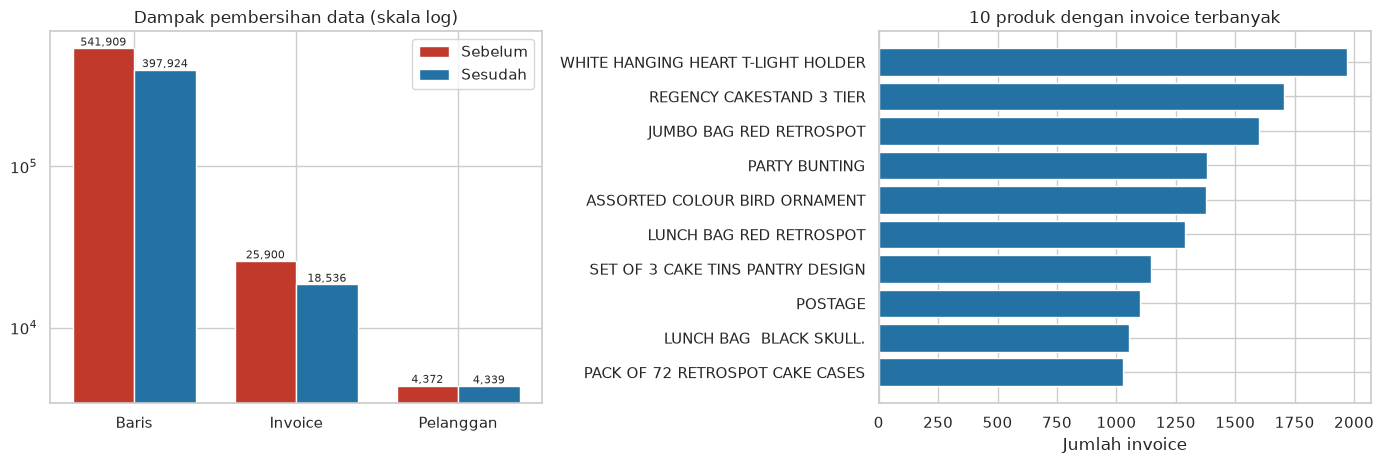

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

labels = ["Baris", "Invoice", "Pelanggan"]
raw_vals = [before["baris"], before["invoice"], before["pelanggan"]]
clean_vals = [after["baris"], after["invoice"], after["pelanggan"]]
x = np.arange(3); w = 0.38
axes[0].bar(x - w/2, raw_vals, w, label="Sebelum", color="#c0392b")
axes[0].bar(x + w/2, clean_vals, w, label="Sesudah", color="#2471a3")
axes[0].set_yscale("log"); axes[0].set_xticks(x); axes[0].set_xticklabels(labels)
axes[0].set_title("Dampak pembersihan data (skala log)"); axes[0].legend()
for i, (a, b) in enumerate(zip(raw_vals, clean_vals)):
    axes[0].text(i - w/2, a, f"{a:,}", ha="center", va="bottom", fontsize=8)
    axes[0].text(i + w/2, b, f"{b:,}", ha="center", va="bottom", fontsize=8)

top = df_clean.groupby("Description")["InvoiceNo"].nunique().nlargest(10)[::-1]
axes[1].barh([t[:34] for t in top.index], top.values, color="#2471a3")
axes[1].set_title("10 produk dengan invoice terbanyak"); axes[1].set_xlabel("Jumlah invoice")
plt.tight_layout(); plt.show()

## 4. Persiapan Data untuk Sequential Pattern Mining

Data diurutkan berdasarkan `CustomerID` dan `InvoiceDate`; produk dalam satu invoice digabung menjadi satu itemset (tanpa duplikat, dan diurutkan alfabetis agar representasinya konsisten). Setiap pelanggan menjadi satu sequence berupa *list of list* (daftar itemset berurutan waktu).

In [6]:
inv = (df_clean.groupby(["CustomerID", "InvoiceNo"])
       .agg(date=("InvoiceDate", "min"),
            items=("Description", lambda s: tuple(sorted(set(s)))))
       .reset_index()
       .sort_values(["CustomerID", "date", "InvoiceNo"]))

# satu sequence per pelanggan: list of itemset (itemset = tuple produk terurut)
customer_ids = inv["CustomerID"].drop_duplicates().tolist()
sequences = [list(x) for x in inv.groupby("CustomerID", sort=False)["items"].apply(list)]
n_customers = len(sequences)
print("Jumlah sequence (pelanggan):", n_customers)

# contoh: satu pelanggan dengan 3 invoice pertama
example = next(s for s in sequences if 3 <= len(s) <= 4)
for k, itemset in enumerate(example, 1):
    print(f"Invoice ke-{k}: {len(itemset)} produk -> {list(itemset)[:3]}{' ...' if len(itemset) > 3 else ''}")

Jumlah sequence (pelanggan): 4339
Invoice ke-1: 13 produk -> ['60 CAKE CASES DOLLY GIRL DESIGN', '60 CAKE CASES VINTAGE CHRISTMAS', '60 TEATIME FAIRY CAKE CASES'] ...
Invoice ke-2: 6 produk -> ['MULTI HEARTS  STICKERS', 'PACK OF 12 BLUE PAISLEY TISSUES', 'PACK OF 12 HEARTS DESIGN TISSUES'] ...
Invoice ke-3: 5 produk -> ['DOUGHNUT LIP GLOSS', 'ICE CREAM PEN LIP GLOSS', 'ICE CREAM SUNDAE LIP GLOSS'] ...
Invoice ke-4: 3 produk -> ['DOUGHNUT LIP GLOSS', 'ICE CREAM PEN LIP GLOSS', 'POSTAGE']


Invoice per pelanggan : rata-rata 4.27, median 2, maks 210
Produk per invoice    : rata-rata 20.9, median 15
Pelanggan dengan 1 invoice saja: 1,494 (34.4%) -> tidak bisa membentuk pola berurutan


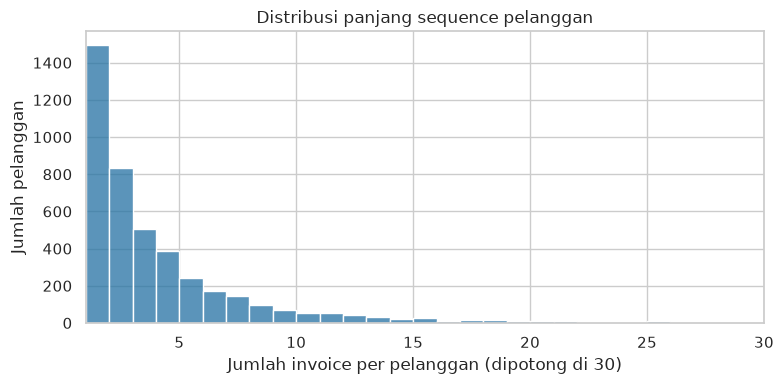

In [7]:
seq_len = np.array([len(s) for s in sequences])             # jumlah invoice per pelanggan
items_per_inv = np.array([len(e) for s in sequences for e in s])
print(f"Invoice per pelanggan : rata-rata {seq_len.mean():.2f}, median {np.median(seq_len):.0f}, maks {seq_len.max()}")
print(f"Produk per invoice    : rata-rata {items_per_inv.mean():.1f}, median {np.median(items_per_inv):.0f}")
print(f"Pelanggan dengan 1 invoice saja: {(seq_len == 1).sum():,} ({(seq_len == 1).mean():.1%}) -> tidak bisa membentuk pola berurutan")

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(seq_len, bins=range(1, 31), color="#2471a3", ax=ax)
ax.set(xlim=(1, 30), xlabel="Jumlah invoice per pelanggan (dipotong di 30)", ylabel="Jumlah pelanggan",
       title="Distribusi panjang sequence pelanggan")
plt.tight_layout(); plt.show()

## 5. Algoritma PrefixSpan

**PrefixSpan** membangun pola secara bertahap: mulai dari pola kosong, ia mencari item frequent lalu menumbuhkan pola tersebut dengan dua cara:
- **S-extension:** menambah item sebagai itemset *baru* di belakang pola (kunjungan berikutnya).
- **I-extension:** menambah item ke itemset *terakhir* pola (dibeli bersamaan dalam invoice yang sama).

Pada tiap langkah, hanya data "sisa" setelah awalan (*projected database*) yang diperiksa, dan pola yang support-nya di bawah minimum langsung dipangkas (sifat *anti-monotone*: sub-pola dari pola frequent juga frequent). Fungsi di bawah mengembalikan dictionary `{pola: jumlah pelanggan}`.

In [8]:
def prefixspan(sequences, min_count, max_len=None):
    """PrefixSpan untuk sequence berisi itemset.
    sequences : list (pelanggan) of list (invoice) of tuple (produk terurut)
    min_count : jumlah pelanggan minimum yang memuat pola (support absolut)
    max_len   : batas jumlah total item dalam pola (None = tanpa batas)
    return    : {pola (tuple of tuple): jumlah pelanggan}
    """
    # 1. buang item yang sendirinya tidak frequent (tidak mungkin ada di pola frequent)
    item_sup = Counter(it for s in sequences for it in {i for e in s for i in e})
    keep = {i for i, c in item_sup.items() if c >= min_count}
    seqs = []
    for s in sequences:
        es = [frozenset(i for i in e if i in keep) for e in s]
        seqs.append([e for e in es if e])

    out = {}

    def count_items(pattern, proj):
        s_sup, i_sup = defaultdict(int), defaultdict(int)
        last = frozenset(pattern[-1]) if pattern else None
        for si, prev_end, end in proj:
            seq = seqs[si]
            seen = set()                                   # s-extension: item di invoice setelah 'end'
            for e in range(end + 1, len(seq)):
                seen.update(seq[e])
            for it in seen:
                s_sup[it] += 1
            if pattern:                                    # i-extension: item di invoice yang memuat itemset terakhir
                seen = set()
                for e in range(end, len(seq)):
                    if last <= seq[e]:
                        seen.update(it for it in seq[e] if it > pattern[-1][-1])
                for it in seen:
                    i_sup[it] += 1
        return s_sup, i_sup

    def grow(pattern, proj, n_items):
        if max_len is not None and n_items >= max_len:
            return
        s_sup, i_sup = count_items(pattern, proj)
        for it, c in s_sup.items():                        # S-extension
            if c < min_count:
                continue
            new = pattern + ((it,),)
            out[new] = c
            nproj = []
            for si, prev_end, end in proj:
                seq = seqs[si]
                for e in range(end + 1, len(seq)):
                    if it in seq[e]:
                        nproj.append((si, end, e)); break
            grow(new, nproj, n_items + 1)
        for it, c in i_sup.items():                        # I-extension
            if c < min_count:
                continue
            new = pattern[:-1] + (pattern[-1] + (it,),)
            out[new] = c
            last = frozenset(pattern[-1]); nproj = []
            for si, prev_end, end in proj:
                seq = seqs[si]
                for e in range(end, len(seq)):
                    if last <= seq[e] and it in seq[e]:
                        nproj.append((si, prev_end, e)); break
            grow(new, nproj, n_items + 1)

    grow((), [(i, -1, -1) for i in range(len(seqs))], 0)
    return out


def n_items(pattern):
    return sum(len(e) for e in pattern)

def fmt(pattern, width=None):
    """Tulis pola sebagai {A, B} -> {C}."""
    def cut(x): return x if width is None or len(x) <= width else x[:width - 1] + "..."
    return " -> ".join("{" + ", ".join(cut(i) for i in e) + "}" for e in pattern)

### Validasi Implementasi

Sebelum dipakai pada dataset asli, implementasi diuji pada (a) contoh kecil dengan hasil yang dapat dihitung manual, dan (b) 20 dataset acak kecil yang hasilnya dibandingkan dengan perhitungan **brute-force** (menghitung support semua kandidat pola secara langsung).

In [9]:
def contains(seq, pattern):
    """Apakah sequence memuat pola? (itemset pola harus subset dari itemset invoice, urutan terjaga)"""
    pos = 0
    for p in pattern:
        while pos < len(seq) and not set(p) <= set(seq[pos]):
            pos += 1
        if pos == len(seq):
            return False
        pos += 1
    return True

# (a) contoh kecil
toy = [[("a",), ("b", "c"), ("a",)],
       [("a",), ("c",)],
       [("b",), ("a", "c")],
       [("a", "b"), ("c",)]]
toy_res = prefixspan(toy, min_count=1)      # min_count=1 agar semua pola tampil dan bisa dibandingkan
for p in [(("a",), ("c",)), (("a",), ("b", "c")), (("a",), ("a",)), (("b",), ("c",))]:
    print(f"{fmt(p):18s} support = {toy_res.get(p, 0)}  | brute-force = {sum(contains(s, p) for s in toy)}")

# (b) uji acak vs brute-force
random.seed(1)
alphabet = list("abcde")
subsets = [c for r in range(1, 4) for c in itertools.combinations(alphabet, r)]
ok = True
for trial in range(20):
    data = [[tuple(sorted(random.sample(alphabet, random.randint(1, 3)))) for _ in range(random.randint(1, 5))]
            for _ in range(random.randint(8, 25))]
    mc = random.randint(2, 5)
    got = {p: c for p, c in prefixspan(data, mc).items() if len(p) <= 3 and all(len(e) <= 3 for e in p)}
    exp = {}
    for L in (1, 2, 3):
        for pat in itertools.product(subsets, repeat=L):
            c = sum(contains(s, pat) for s in data)
            if c >= mc:
                exp[pat] = c
    ok &= (got == exp)
print("\nPrefixSpan sama persis dengan brute-force pada 20 dataset acak:", ok)
assert ok

{a} -> {c}         support = 3  | brute-force = 3
{a} -> {b, c}      support = 1  | brute-force = 1
{a} -> {a}         support = 1  | brute-force = 1
{b} -> {c}         support = 2  | brute-force = 2



PrefixSpan sama persis dengan brute-force pada 20 dataset acak: True


## 6. Penerapan PrefixSpan dan Penyesuaian Minimum Support

Titik awal yang diminta tugas adalah **minimum support = 0,01** (relatif terhadap jumlah pelanggan). Berikut perbandingan beberapa nilai untuk melihat apakah jumlah pola masih masuk akal.

Catatan: pola dengan satu itemset (mis. `{A, B}`) hanyalah barang yang dibeli bersamaan dalam satu invoice (asosiasi biasa). Pola **berurutan** yang sebenarnya adalah pola dengan **minimal dua itemset** (dua invoice berbeda), dan itulah yang dianalisis di Bagian 7. Pada support 0,01 pola dibatasi maksimal 3 item (`max_len=3`) agar waktu hitung wajar, jadi jumlahnya adalah batas bawah.

,min_support,min_pelanggan,max_len,total_pola,pola_berurutan (>=2 itemset),waktu (detik)
0,0.05,217,-,306,9,2.5
1,0.03,131,-,1259,333,10.1
2,0.02,87,-,5176,2976,35.7
3,0.01,44,3,59121,49497,113.0


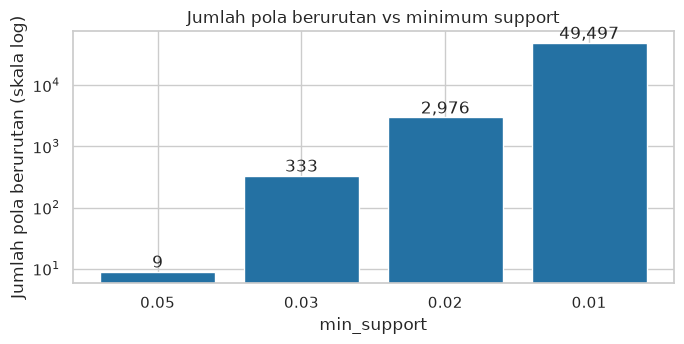

In [10]:
runs = {}
rows = []
for sup, ml in [(0.05, None), (0.03, None), (0.02, None), (0.01, 3)]:
    min_count = int(np.ceil(sup * n_customers))
    t0 = time.time()
    res = prefixspan(sequences, min_count, max_len=ml)
    runs[sup] = res
    seq_pat = sum(1 for p in res if len(p) >= 2)
    rows.append({"min_support": sup, "min_pelanggan": min_count, "max_len": ml or "-",
                 "total_pola": len(res), "pola_berurutan (>=2 itemset)": seq_pat,
                 "waktu (detik)": round(time.time() - t0, 1)})
sweep = pd.DataFrame(rows)
display(sweep)

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar([f"{r['min_support']}" for r in rows], [r["pola_berurutan (>=2 itemset)"] for r in rows], color="#2471a3")
ax.set_yscale("log"); ax.set(xlabel="min_support", ylabel="Jumlah pola berurutan (skala log)",
                              title="Jumlah pola berurutan vs minimum support")
for i, r in enumerate(rows):
    ax.text(i, r["pola_berurutan (>=2 itemset)"], f"{r['pola_berurutan (>=2 itemset)']:,}", ha="center", va="bottom")
plt.tight_layout(); plt.show()

### Analisis Pemilihan Minimum Support

| min_support | Pelanggan minimum | Pola berurutan | Penilaian |
|---|---|---|---|
| 0,05 | 217 | 9 | Terlalu sedikit: kesembilannya hanya pembelian ulang produk terlaris yang sama |
| 0,03 | 131 | 333 | Masih agak sempit |
| **0,02** | **87** | **2.976** | **Dipilih**: jumlah pola cukup untuk dianalisis, ada pola lintas produk dan pola sampai 4 invoice |
| 0,01 (titik awal) | 44 | 49.497 (batas bawah, `max_len=3`) | Terlalu banyak: puluhan ribu pola, sebagian besar variasi warna/desain dari produk yang sama |

Pada **0,01** (titik awal tugas), PrefixSpan sudah menghasilkan 59.121 pola total (49.497 di antaranya berurutan) walaupun panjangnya hanya dibatasi sampai 3 item, dan butuh sekitar 108 detik. Jumlah sebesar ini tidak dapat diinterpretasikan satu per satu, dan pola yang muncul didominasi duplikasi varian produk. Pada **0,05** hanya 9 pola yang lolos dan semuanya sekadar pembelian ulang produk terlaris, sehingga tidak ada informasi lintas produk. Maka dipilih **min_support = 0,02** (minimal 87 dari 4.339 pelanggan): menghasilkan 5.176 pola frequent (2.976 berurutan) dalam sekitar 31 detik, tanpa batas panjang, dengan kombinasi pola pembelian ulang dan pola lintas produk.

In [11]:
MIN_SUPPORT = 0.02
min_count = int(np.ceil(MIN_SUPPORT * n_customers))
support_count = runs[MIN_SUPPORT]                  # hasil PrefixSpan tanpa batas panjang

def antecedent(p):
    """Pola tanpa item terakhirnya (awalan)."""
    return p[:-1] if len(p[-1]) == 1 else p[:-1] + (p[-1][:-1],)

records = []
for p, c in support_count.items():
    if len(p) < 2:
        continue                                    # hanya pola berurutan (>= 2 invoice)
    ante = antecedent(p)
    records.append({"pola": p, "n_item": n_items(p), "n_invoice": len(p),
                    "support_count": c, "support": c / n_customers,
                    "antecedent_support": support_count[ante] / n_customers,
                    "confidence": c / support_count[ante],
                    "jenis": "pembelian ulang" if len({i for e in p for i in e}) == 1 else "lintas produk"})
patterns = pd.DataFrame(records)
patterns["pola_teks"] = patterns["pola"].map(fmt)
print(f"min_support = {MIN_SUPPORT} -> pelanggan minimum = {min_count} dari {n_customers:,}")
print(f"Total pola frequent: {len(support_count):,} | pola berurutan (>=2 invoice): {len(patterns):,}")
display(patterns.groupby(["n_invoice", "jenis"]).size().unstack(fill_value=0).rename_axis("jumlah invoice dalam pola"))

min_support = 0.02 -> pelanggan minimum = 87 dari 4,339
Total pola frequent: 5,176 | pola berurutan (>=2 invoice): 2,976


jenis,lintas produk,pembelian ulang
jumlah invoice dalam pola,,
2,2366,136
3,443,24
4,2,5


## 7. Evaluasi Pola Berurutan

Semua pola berurutan diurutkan berdasarkan support. Tabel berikut menampilkan 20 pola teratas beserta support dan confidence-nya.

In [12]:
show = ["pola_teks", "support_count", "support", "confidence", "jenis"]
top20 = patterns.sort_values(["support_count", "confidence"], ascending=False).head(20).reset_index(drop=True)
top20.index += 1
display(top20[show].round(4))

,pola_teks,support_count,support,confidence,jenis
1,{WHITE HANGING HEART T-LIGHT HOLDER} -> {WHITE HANGING HEART T-LIGHT HOLDER},405,0.0933,0.4731,pembelian ulang
2,{REGENCY CAKESTAND 3 TIER} -> {REGENCY CAKESTAND 3 TIER},330,0.0761,0.3746,pembelian ulang
3,{JUMBO BAG RED RETROSPOT} -> {JUMBO BAG RED RETROSPOT},312,0.0719,0.4913,pembelian ulang
4,{ASSORTED COLOUR BIRD ORNAMENT} -> {ASSORTED COLOUR BIRD ORNAMENT},291,0.0671,0.4292,pembelian ulang
5,{PARTY BUNTING} -> {PARTY BUNTING},280,0.0645,0.3955,pembelian ulang
6,{LUNCH BAG RED RETROSPOT} -> {LUNCH BAG RED RETROSPOT},276,0.0636,0.5188,pembelian ulang
7,{LUNCH BAG BLACK SKULL.} -> {LUNCH BAG BLACK SKULL.},229,0.0528,0.5000,pembelian ulang
8,{SET OF 3 CAKE TINS PANTRY DESIGN} -> {SET OF 3 CAKE TINS PANTRY DESIGN},225,0.0519,0.3516,pembelian ulang
9,{WHITE HANGING HEART T-LIGHT HOLDER} -> {WHITE HANGING HEART T-LIGHT HOLDER} -> {WHITE HANGING HEART T-LIGHT HOLDER},222,0.0512,0.5481,pembelian ulang
10,{LUNCH BAG RED RETROSPOT} -> {LUNCH BAG BLACK SKULL.},212,0.0489,0.3985,lintas produk


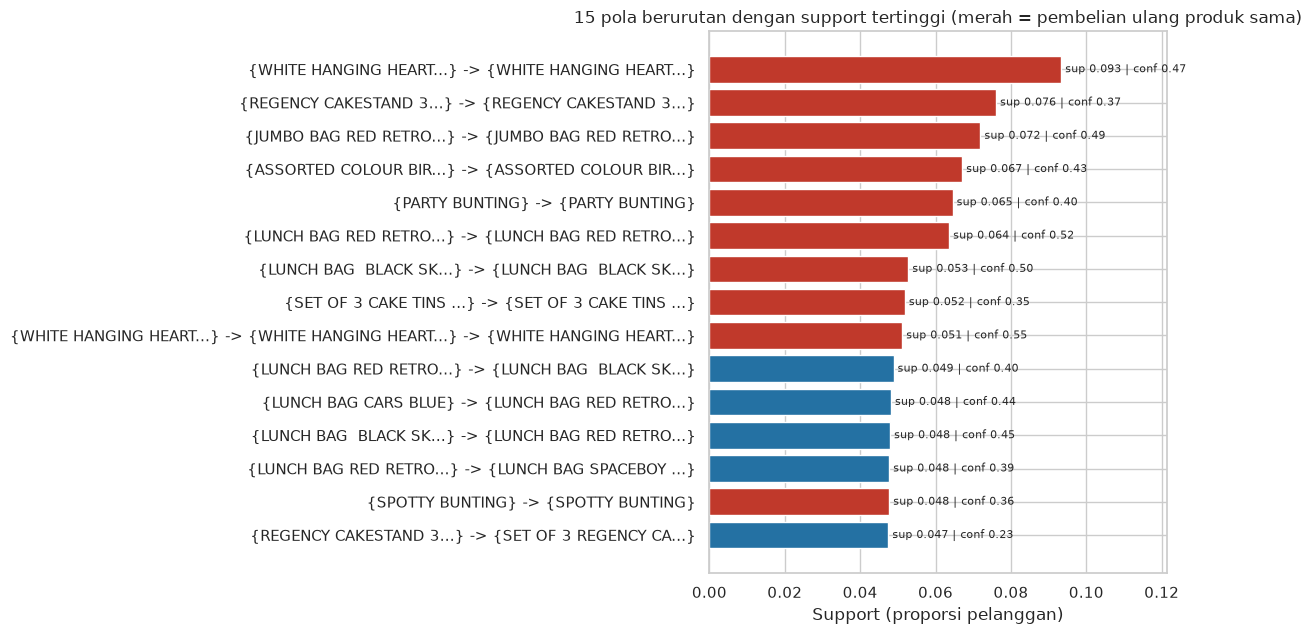

In [13]:
top15 = patterns.sort_values(["support_count", "confidence"], ascending=False).head(15)[::-1]
fig, ax = plt.subplots(figsize=(12, 6.5))
colors = ["#c0392b" if j == "pembelian ulang" else "#2471a3" for j in top15["jenis"]]
ax.barh([fmt(p, 20) for p in top15["pola"]], top15["support"], color=colors)
for y, (s, c) in enumerate(zip(top15["support"], top15["confidence"])):
    ax.text(s, y, f" sup {s:.3f} | conf {c:.2f}", va="center", fontsize=8)
ax.set(xlabel="Support (proporsi pelanggan)", title="15 pola berurutan dengan support tertinggi (merah = pembelian ulang produk sama)")
ax.set_xlim(0, top15["support"].max() * 1.3)
plt.tight_layout(); plt.show()

In [14]:
best3 = patterns.sort_values(["support_count", "confidence"], ascending=False).head(3)
for rank, (_, r) in enumerate(best3.iterrows(), 1):
    print(f"#{rank}  {r['pola_teks']}")
    print(f"     support    = {r['support']:.4f} ({r['support_count']} dari {n_customers:,} pelanggan)")
    print(f"     antecedent = {r['antecedent_support']:.4f} -> confidence = {r['confidence']:.3f}")
    print(f"     jenis      = {r['jenis']}\n")

#1  {WHITE HANGING HEART T-LIGHT HOLDER} -> {WHITE HANGING HEART T-LIGHT HOLDER}
     support    = 0.0933 (405 dari 4,339 pelanggan)
     antecedent = 0.1973 -> confidence = 0.473
     jenis      = pembelian ulang

#2  {REGENCY CAKESTAND 3 TIER} -> {REGENCY CAKESTAND 3 TIER}
     support    = 0.0761 (330 dari 4,339 pelanggan)
     antecedent = 0.2030 -> confidence = 0.375
     jenis      = pembelian ulang

#3  {JUMBO BAG RED RETROSPOT} -> {JUMBO BAG RED RETROSPOT}
     support    = 0.0719 (312 dari 4,339 pelanggan)
     antecedent = 0.1463 -> confidence = 0.491
     jenis      = pembelian ulang



### Interpretasi Tiga Pola dengan Support Tertinggi

Ketiga pola teratas semuanya adalah **pembelian ulang produk yang sama** pada invoice yang berbeda:

1. **`{WHITE HANGING HEART T-LIGHT HOLDER} -> {WHITE HANGING HEART T-LIGHT HOLDER}`** (support 0,0933; confidence 0,473). Sebanyak 405 pelanggan (9,3% dari seluruh pelanggan) membeli produk ini di dua invoice berbeda. Dari 19,7% pelanggan yang pernah membeli produk ini, hampir separuh (47,3%) membelinya lagi pada invoice yang lebih belakangan. Produk ini juga yang paling sering muncul di seluruh invoice, jadi ini produk andalan toko yang berulang kali dibeli. Implikasi bisnis: ketersediaan stok produk ini harus dijaga, dan pelanggan yang baru membelinya cocok diberi pengingat atau penawaran paket untuk pembelian berikutnya.
2. **`{REGENCY CAKESTAND 3 TIER} -> {REGENCY CAKESTAND 3 TIER}`** (support 0,0761; confidence 0,375). Sekitar 7,6% pelanggan membeli etalase kue ini lebih dari sekali; dari 20,3% pembeli pertamanya, 37,5% kembali membeli. Barang ini tergolong tahan lama, sehingga pembelian ulangnya kemungkinan datang dari pelanggan grosir/pedagang yang mengisi ulang stok (Online Retail memang banyak melayani pelanggan grosir). Implikasi bisnis: potensi program harga grosir atau diskon pembelian berulang.
3. **`{JUMBO BAG RED RETROSPOT} -> {JUMBO BAG RED RETROSPOT}`** (support 0,0719; confidence 0,491). Tas ini punya tingkat pembelian ulang paling tinggi di antara tiga besar: sekitar separuh pembelinya (49,1%) membelinya lagi. Implikasi bisnis: produk ini cocok dijadikan produk "pancingan" dan untuk cross-sell produk sejenis (tas lain seri Retrospot).

Perlu dicatat bahwa support tertinggi bukan berarti paling informatif. Pola pembelian ulang menunjukkan loyalitas dan kebutuhan restock, tetapi tidak menjawab "setelah A, produk apa yang dibeli berikutnya". Karena itu tabel berikut menampilkan pola **lintas produk** secara terpisah.

In [15]:
cross = patterns[patterns["jenis"] == "lintas produk"]
print("Pola lintas produk dengan support tertinggi:")
top_cross = cross.sort_values(["support_count", "confidence"], ascending=False).head(10).reset_index(drop=True)
top_cross.index += 1
display(top_cross[["pola_teks", "support_count", "support", "confidence"]].round(4))

print("\nPola 2 invoice dengan confidence tertinggi:")
conf_top = patterns[patterns["n_invoice"] == 2].sort_values(["confidence", "support_count"], ascending=False).head(10).reset_index(drop=True)
conf_top.index += 1
display(conf_top[["pola_teks", "support_count", "support", "confidence", "jenis"]].round(4))

Pola lintas produk dengan support tertinggi:


,pola_teks,support_count,support,confidence
1,{LUNCH BAG RED RETROSPOT} -> {LUNCH BAG BLACK SKULL.},212,0.0489,0.3985
2,{LUNCH BAG CARS BLUE} -> {LUNCH BAG RED RETROSPOT},209,0.0482,0.4363
3,{LUNCH BAG BLACK SKULL.} -> {LUNCH BAG RED RETROSPOT},208,0.0479,0.4541
4,{LUNCH BAG RED RETROSPOT} -> {LUNCH BAG SPACEBOY DESIGN},207,0.0477,0.3891
5,{REGENCY CAKESTAND 3 TIER} -> {SET OF 3 REGENCY CAKE TINS},206,0.0475,0.2338
6,{LUNCH BAG RED RETROSPOT} -> {LUNCH BAG SUKI DESIGN},203,0.0468,0.3816
7,{LUNCH BAG PINK POLKADOT} -> {LUNCH BAG RED RETROSPOT},201,0.0463,0.4527
8,{JUMBO BAG RED RETROSPOT} -> {JUMBO BAG VINTAGE DOILY},201,0.0463,0.3165
9,{JUMBO BAG RED RETROSPOT} -> {LUNCH BAG RED RETROSPOT},200,0.0461,0.3150
10,{LUNCH BAG SPACEBOY DESIGN} -> {LUNCH BAG RED RETROSPOT},198,0.0456,0.4041



Pola 2 invoice dengan confidence tertinggi:


,pola_teks,support_count,support,confidence,jenis
1,"{GARDENERS KNEELING PAD CUP OF TEA, GARDENERS KNEELING PAD KEEP CALM} -> {GARDENERS KNEELING PAD CUP OF TEA, GARDENERS KNEELING PAD KEEP CALM}",96,0.0221,0.9412,lintas produk
2,"{ALARM CLOCK BAKELIKE GREEN, ALARM CLOCK BAKELIKE RED} -> {ALARM CLOCK BAKELIKE GREEN, ALARM CLOCK BAKELIKE RED}",127,0.0293,0.9407,lintas produk
3,"{REGENCY CAKESTAND 3 TIER} -> {REGENCY TEA PLATE GREEN, REGENCY TEA PLATE ROSES}",94,0.0217,0.9307,lintas produk
4,"{DOLLY GIRL LUNCH BOX, SPACEBOY LUNCH BOX} -> {DOLLY GIRL LUNCH BOX, SPACEBOY LUNCH BOX}",90,0.0207,0.9184,lintas produk
5,"{GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY TEACUP AND SAUCER} -> {GREEN REGENCY TEACUP AND SAUCER, PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY TEACUP AND SAUCER}",89,0.0205,0.9175,lintas produk
6,"{ALARM CLOCK BAKELIKE PINK, ALARM CLOCK BAKELIKE RED} -> {ALARM CLOCK BAKELIKE GREEN, ALARM CLOCK BAKELIKE RED}",103,0.0237,0.9115,lintas produk
7,"{GARDENERS KNEELING PAD KEEP CALM} -> {GARDENERS KNEELING PAD CUP OF TEA, GARDENERS KNEELING PAD KEEP CALM}",109,0.0251,0.9083,lintas produk
8,"{ALARM CLOCK BAKELIKE PINK, ALARM CLOCK BAKELIKE RED} -> {ALARM CLOCK BAKELIKE PINK, ALARM CLOCK BAKELIKE RED}",97,0.0224,0.9065,lintas produk
9,"{ALARM CLOCK BAKELIKE GREEN} -> {ALARM CLOCK BAKELIKE GREEN, ALARM CLOCK BAKELIKE PINK, ALARM CLOCK BAKELIKE RED}",89,0.0205,0.8990,lintas produk
10,"{LUNCH BAG BLACK SKULL., LUNCH BAG PINK POLKADOT, LUNCH BAG RED RETROSPOT} -> {LUNCH BAG PINK POLKADOT, LUNCH BAG RED RETROSPOT}",89,0.0205,0.8990,lintas produk


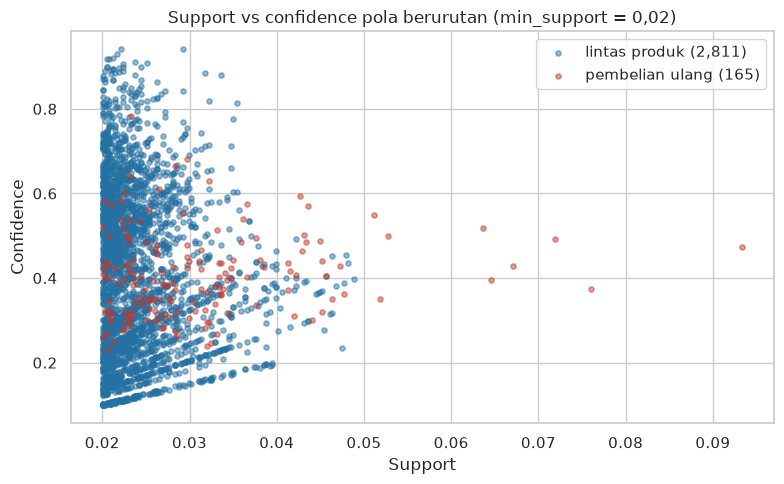

        support  confidence
count  2976.000    2976.000
mean      0.024       0.415
std       0.005       0.189
min       0.020       0.099
25%       0.021       0.252
50%       0.023       0.401
75%       0.026       0.560
max       0.093       0.941

Rata-rata confidence per jenis:


                 count   mean  median
jenis                                
lintas produk     2811  0.415   0.401
pembelian ulang    165  0.405   0.395


In [16]:
fig, ax = plt.subplots(figsize=(8, 5))
for j, c in [("lintas produk", "#2471a3"), ("pembelian ulang", "#c0392b")]:
    sub = patterns[patterns["jenis"] == j]
    ax.scatter(sub["support"], sub["confidence"], s=14, alpha=0.5, color=c, label=f"{j} ({len(sub):,})")
ax.set(xlabel="Support", ylabel="Confidence", title="Support vs confidence pola berurutan (min_support = 0,02)")
ax.legend()
plt.tight_layout(); plt.show()
print(patterns[["support", "confidence"]].describe().round(3))
print("\nRata-rata confidence per jenis:"); print(patterns.groupby("jenis")["confidence"].agg(["count", "mean", "median"]).round(3))

### Analisis Evaluasi Pola Berurutan

- **Support rendah secara umum.** Rata-rata support pola hanya 0,024 (median 0,023, maksimum 0,093). Penyebabnya, 1.494 pelanggan (34,4%) hanya punya satu invoice sehingga tidak dapat mendukung pola berurutan apa pun, dan pembelian tersebar di 3.866 produk berbeda. Karena itu pola berurutan dengan support di atas 0,05 hanya ada 9 buah.
- **Confidence cukup bervariasi.** Rata-rata confidence 0,415 (median 0,401, maksimum 0,941): untuk pola berurutan rata-rata, sekitar 40% pelanggan yang menjalani bagian awal pola akan melengkapinya. Pembelian ulang (rata-rata 0,405) dan lintas produk (0,415) hampir sama kuatnya. Pada scatter plot, support tinggi (> 0,05) hanya dimiliki pola pembelian ulang (titik merah), sedangkan pola lintas produk berkumpul pada support 0,02 sampai 0,05 dengan confidence yang tersebar luas.
- **Pola lintas produk terkuat: keluarga LUNCH BAG.** Pelanggan yang membeli satu desain *lunch bag* cenderung kembali membeli desain lain, misalnya `{LUNCH BAG RED RETROSPOT} -> {LUNCH BAG BLACK SKULL.}` (support 0,0489; confidence 0,399), `{LUNCH BAG CARS BLUE} -> {LUNCH BAG RED RETROSPOT}` (0,0482; 0,436), dan `{LUNCH BAG BLACK SKULL.} -> {LUNCH BAG RED RETROSPOT}` (0,0479; 0,454). Ini menunjukkan perilaku melengkapi koleksi desain. Pola lintas kategori yang paling menonjol adalah `{REGENCY CAKESTAND 3 TIER} -> {SET OF 3 REGENCY CAKE TINS}` (support 0,0475; confidence 0,234), yaitu pembeli etalase kue yang kemudian membeli set loyang dari seri yang sama, serta `{JUMBO BAG RED RETROSPOT} -> {JUMBO BAG VINTAGE DOILY}` (0,0463; 0,317).
- **Confidence tertinggi (0,90 sampai 0,94)** dimiliki pola dengan itemset berisi beberapa varian produk dari satu lini (mis. seri *Gardeners Kneeling Pad*, *Alarm Clock Bakelike*, dan *Regency Tea/Teacup*). Support-nya hanya 0,02 sampai 0,03 karena produknya khusus; pelanggan yang membeli beberapa varian lini tersebut hampir selalu membeli varian lini yang sama lagi di kunjungan berikutnya, yaitu loyalitas pada satu lini produk.
- **Keterbatasan.** (1) Pola tidak dibatasi jarak waktu, jadi A lalu B bisa berjarak beberapa bulan dalam periode 12 bulan. (2) Variasi nama produk (warna/desain) memecah satu lini menjadi banyak produk sehingga menghasilkan banyak pola mirip. (3) Banyak pelanggan adalah grosir sehingga pola pembelian ulang bisa mencerminkan restock, bukan preferensi konsumen akhir. (4) Support dihitung per pelanggan, sehingga pelanggan yang sering belanja tidak dihitung lebih dari sekali.

## 8. Kesimpulan

1. **Pembersihan data.** Dari 541.909 baris, 25.900 invoice, dan 4.372 pelanggan, tersisa **397.924 baris, 18.536 invoice, dan 4.339 pelanggan** (26,6% baris dihapus). Pengurangan terbesar berasal dari baris tanpa `CustomerID` (132.769 baris), yang memang harus dibuang karena sequence disusun per pelanggan. Terdapat 3.866 produk unik setelah nama diseragamkan.
2. **Sequence pelanggan.** Terbentuk 4.339 sequence. Pelanggan rata-rata punya 4,27 invoice (median 2, maksimum 210), dan 34,4% pelanggan hanya punya satu invoice sehingga tidak dapat membentuk pola berurutan.
3. **Algoritma dan parameter.** PrefixSpan diimplementasikan sendiri agar mendukung itemset dan diverifikasi sama dengan perhitungan brute-force. Minimum support awal 0,01 menghasilkan puluhan ribu pola, sedangkan 0,05 hanya 9 pola, sehingga dipilih **0,02** (5.176 pola frequent; 2.976 di antaranya berurutan).
4. **Temuan utama.** Tiga pola dengan support tertinggi semuanya pembelian ulang produk yang sama: WHITE HANGING HEART T-LIGHT HOLDER (support 0,0933; confidence 0,473), REGENCY CAKESTAND 3 TIER (0,0761; 0,375), dan JUMBO BAG RED RETROSPOT (0,0719; 0,491). Pola lintas produk didominasi keluarga *lunch bag* (pelanggan melengkapi koleksi desain, confidence 0,40 sampai 0,45) dan pasangan *Regency cakestand* menuju *Regency cake tins*.
5. **Implikasi bisnis.** (a) Jaga stok produk andalan yang sering dibeli ulang dan tawarkan paket atau diskon pembelian ulang. (b) Setelah pelanggan membeli satu desain *lunch bag*/tas, rekomendasikan desain lain dari seri yang sama. (c) Tawarkan seri pelengkap (mis. *cake tins*) kepada pembeli *cakestand*.
6. **Keterbatasan dan saran.** Pola belum dibatasi jarak waktu antar pembelian, dan variasi warna/desain memecah lini produk. Eksperimen lanjutan: menambahkan batas minimum/maksimum jarak waktu antar invoice, memakai pola *closed*/*maximal* untuk mengurangi redundansi, menggabungkan varian produk ke dalam kategori, memisahkan pelanggan grosir dan eceran (mis. per `Country`), serta membandingkan dengan algoritma GSP.